# Trading ERCOT congestion with PTP Obligations

*Applied Algorithmic Trading, group project.*

## Overview

**How the Texas power market works (simplified).** Each hour, power has a price at each hub (West, North, …):
- **Day-ahead (DA) price**: set the day before in an auction, from forecasts. It's the *plan*.
- **Real-time (RT) price**: set on the day from what actually happens. It's the *reality*.

**Congestion.** West Texas has lots of wind, Dallas (North) has lots of demand. When the power lines between
them are full, North gets more expensive than West.

**Our trade: a PTP Obligation West→North.** Bought in the DA auction, settled at RT prices. Per MW and hour:

> **profit = RT gap − DA gap** (gap = North price − West price)

So profit is **how wrong the auction was about congestion**: the *auction's error*. We forecast it for each hour
of tomorrow. If the forecast is clearly positive we buy West→North; if clearly negative, the reverse.

**Rules of the game**
- We bid at 10:00 the day before, and use only information available then.
- We tune on 2024 and test on 2025–2026.
- We pay a $0.50/MWh fee.

**Result in one line:** we forecast the error better than the alternatives, but not well enough to beat fees.

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from backtest import LABELS, block_bootstrap
from compare_models import OUT, pinball
from config import OUTPUT, PERIODS, QCOLS, QUANTILES
from covariates import load_covariates
from processing import load_hourly
from spreads import build_spreads

COLORS = {"lgbm": "#2a78d6", "chronos": "#eb6834", "baseline": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#e4e3df", "legend.frameon": False})
FIG = OUTPUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

wn = build_spreads(load_hourly(), [("HB_WEST", "HB_NORTH")])   # one row per hour: da_gap, rt_gap, error
print(f"{len(wn):,} hours, {wn.delivery_date.min():%Y-%m-%d} to {wn.delivery_date.max():%Y-%m-%d}")

25,295 hours, 2023-12-13 to 2026-10-31


## 1. The data

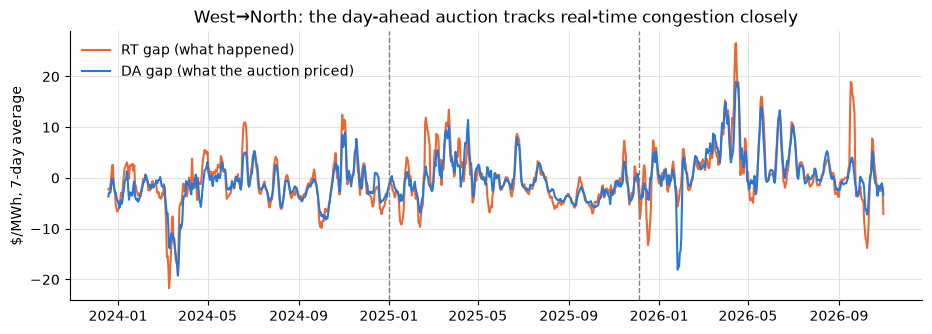

Auction error per hour: mean $0.19, std $11.73, 0.6% of hours beyond ±$50, largest $527


In [2]:
daily = wn.groupby("delivery_date")[["da_gap", "rt_gap", "error"]].mean().rolling(7).mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.rt_gap, color=COLORS["chronos"], label="RT gap (what happened)")
ax.plot(daily.index, daily.da_gap, color=COLORS["lgbm"], label="DA gap (what the auction priced)")
for p in ("test_a", "test_b"):
    ax.axvline(pd.Timestamp(PERIODS[p][0]), color="gray", ls="--", lw=1)
ax.set_ylabel("$/MWh, 7-day average"); ax.legend(loc="upper left")
ax.set_title("West→North: the day-ahead auction tracks real-time congestion closely")
fig.savefig(FIG / "gaps_over_time.png", bbox_inches="tight", dpi=150); plt.show()

e = wn.error
print(f"Auction error per hour: mean ${e.mean():.2f}, std ${e.std():.2f}, "
      f"{(e.abs() > 50).mean():.1%} of hours beyond ±$50, largest ${e.max():.0f}")

- The auction tracks congestion closely, and its error averages about zero.
- A few extreme hours (errors of hundreds of $) dominate totals, so we always show confidence intervals.

**Why West→North?** We tested all 10 hub pairs on 2024 only. West→North made money under every model and has the
clearest story (West wind vs. lines to Dallas). Panhandle pairs were unpredictable.

### The market change in December 2025 (why Test B is separate)

On **5 Dec 2025** ERCOT launched **RTC+B (Real-Time Co-optimization plus Batteries)**, its biggest real-time
market change since 2010:
- Real time now buys power *and* reserves together, every 5 minutes.
- Batteries are modelled properly, including how much charge they have left.
- Congestion should be managed better.

This changes how real-time prices behave, which is the half of our profit we can't see in advance. A model
trained on the old market may not fit the new one. So we report Test A (before) and Test B (after) separately.

In [3]:
wn["period"] = pd.cut(wn.delivery_date, [pd.Timestamp("2023-12-31")] + [pd.Timestamp(PERIODS[p][1]) for p in PERIODS],
                      labels=["2024", "Test A", "Test B (after RTC+B)"])
wn.groupby("period", observed=True).agg(
    avg_DA_gap=("da_gap", "mean"), avg_error=("error", "mean"), error_std=("error", "std"),
    share_hours_error_over_50=("error", lambda e: (e.abs() > 50).mean())).round(3)

,avg_DA_gap,avg_error,error_std,share_hours_error_over_50
period,,,,
2024,-1.875,0.344,10.389,0.006
Test A,-0.834,0.017,9.739,0.004
Test B (after RTC+B),1.844,0.191,14.738,0.009


After the change, the error is about 50% more volatile (std ≈ $15 vs ≈ $10), extreme hours (|error| > $50) are more common (0.9% vs 0.4–0.6%),
and the average DA gap flipped sign. Models trained mostly on the old market face a different game.

## 2. Forecasting models

Each model forecasts tomorrow's 24 hourly errors as a range (10%–90% quantiles), not a single number.

We compare three models, from simplest to most complex:

| Model | Type | How it works |
|---|---|---|
| **Hour-of-day baseline** | simple statistics | For each hour of the day, take the errors of the last 90 days and use their spread as the forecast. No learning. |
| **LightGBM** | decision trees (gradient boosting) | A decision tree asks yes/no questions ("is West wind > 10 GW?", "is it 6 pm?") and ends in a prediction. LightGBM builds hundreds of small trees, each fixing the mistakes of the ones before. We train it on our own data: past errors plus wind/solar/load forecasts. It's retrained monthly. |
| **Chronos-2** (Amazon) | foundation model (neural network) | A transformer, the same kind of network as ChatGPT, but pretrained on huge numbers of time series instead of text. We use it "zero-shot": it only sees the history of our error and predicts what comes next, with no training on our data. |

Why both? Chronos-2 tests whether a big general-purpose model works out of the box. LightGBM tests whether
domain knowledge (wind, load) beats that.

(TimesFM and TabPFN-TS scored like Chronos-2 on 2024, so we dropped them.)

**Scoring.**
- **Pinball loss** measures how good the forecast range is; lower is better.
- **Top-500 PnL** trades 1 MW on each model's 500 most confident hours, after fees.
- **95% interval**: if it contains 0, the profit could be luck.

In [4]:
MODELS = {"lgbm": "lgbm_cov_monthly{s}", "chronos": "chronos_ctx2048_WEST-NORTH{s}",
          "baseline": "baseline_ctx2160{w}{s}"}

def load(model, period):
    s = "" if period == "train" else f"_{period}"
    f = pd.read_csv(OUT / (MODELS[model].format(s=s, w="_WEST-NORTH" if s else "") + ".csv"))
    f = f[f.pair == "HB_WEST->HB_NORTH"]
    f["hour_ending"] = pd.to_datetime(f.hour_ending, utc=True)
    return f.drop(columns="delivery_date").merge(wn, on="hour_ending")

rows = []
for p in PERIODS:
    for m in MODELS:
        f = load(m, p)
        y = f.error.to_numpy()
        top = f.loc[f.q50.abs().nlargest(500).index]
        pnl = np.sign(top.q50) * top.error - 0.5
        days = pnl.groupby(top.delivery_date).sum().reindex(f.delivery_date.unique(), fill_value=0).to_numpy()
        lo, hi = np.percentile(block_bootstrap(days).sum(1), [2.5, 97.5])
        rows.append({"period": p, "model": LABELS[m],
                     "pinball": np.mean([pinball(y, f[c], q).mean() for c, q in zip(QCOLS, QUANTILES)]),
                     "top-500 PnL $": pnl.sum(), "95% interval": f"[{lo:,.0f}, {hi:,.0f}]"})
scores = pd.DataFrame(rows).set_index(["period", "model"])
scores.round(3)

pinball  top-500 PnL $     95% interval
period model                                                           
train  LightGBM + fundamentals    2.192       1763.928     [178, 3,589]
       Chronos-2 (zero-shot)      2.251       1051.155    [-311, 2,661]
       Hour-of-day baseline       2.226        653.595     [-67, 1,363]
test_a LightGBM + fundamentals    2.097        327.378    [-878, 1,710]
       Chronos-2 (zero-shot)      2.187       -243.278      [-861, 382]
       Hour-of-day baseline       2.160         25.654    [-662, 1,177]
test_b LightGBM + fundamentals    2.358        594.055  [-2,164, 4,378]
       Chronos-2 (zero-shot)      2.485      -2109.130   [-4,128, -484]
       Hour-of-day baseline       2.437        230.515  [-1,697, 2,317]

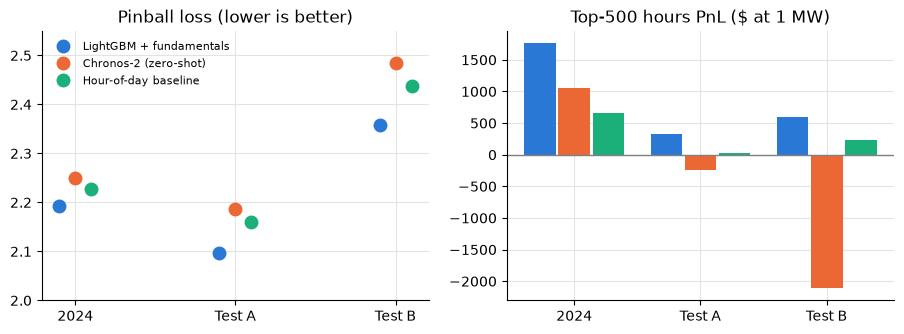

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(3)
for i, m in enumerate(MODELS):
    s = scores.xs(LABELS[m], level="model")
    axes[0].plot(x + (i - 1) * 0.1, s.pinball, "o", ms=9, color=COLORS[m], label=LABELS[m])   # dots: axis doesn't start at 0
    axes[1].bar(x + (i - 1) * 0.27, s["top-500 PnL $"], 0.25, color=COLORS[m])
axes[0].set_ylim(2.0, 2.55); axes[0].set_title("Pinball loss (lower is better)")
axes[1].axhline(0, color="gray", lw=1); axes[1].set_title("Top-500 hours PnL ($ at 1 MW)")
for ax in axes:
    ax.set_xticks(x, ["2024", "Test A", "Test B"])
axes[0].legend(fontsize=8)
fig.savefig(FIG / "model_comparison.png", bbox_inches="tight", dpi=150); plt.show()

- **LightGBM forecasts best in every period** (1.5–3% better than the baseline). Chronos-2 is slightly worse than the baseline.
- Profit is noisy: out of sample every interval contains 0, except Chronos-2's Test B loss.

## 3. Does wind data help?

Thesis: high West wind causes congestion the auction underprices. We group hours by ERCOT's West wind forecast:

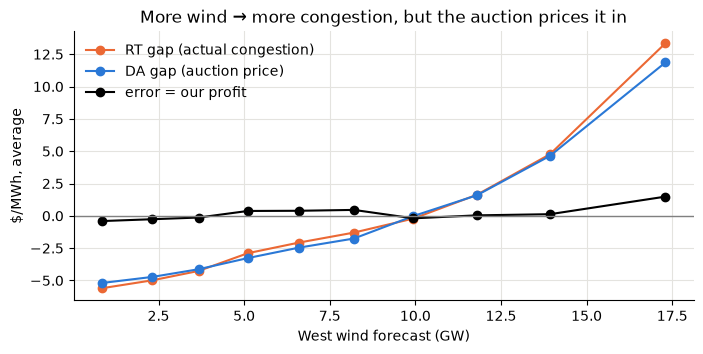

In [6]:
cov = load_covariates()
w = wn.join(cov["wind_west"], on="hour_ending").dropna()
g = w.groupby(pd.qcut(w.wind_west / 1000, 10), observed=True)[["rt_gap", "da_gap", "error"]].mean()
mid = [b.mid for b in g.index]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mid, g.rt_gap, "o-", color=COLORS["chronos"], label="RT gap (actual congestion)")
ax.plot(mid, g.da_gap, "o-", color=COLORS["lgbm"], label="DA gap (auction price)")
ax.plot(mid, g.error, "o-", color="black", label="error = our profit")
ax.axhline(0, color="gray", lw=1); ax.set_xlabel("West wind forecast (GW)"); ax.set_ylabel("$/MWh, average")
ax.set_title("More wind → more congestion, but the auction prices it in"); ax.legend()
fig.savefig(FIG / "wind_priced_in.png", bbox_inches="tight", dpi=150); plt.show()

**Key finding:** more wind does mean more congestion, but the auction prices it in. Everyone sees the same public
forecast, so our profit stays near zero.

The forecasts still make LightGBM a bit more accurate. Extra data (past forecast misses, constraint prices,
outages) didn't help consistently, so the final model is **LightGBM + wind/solar/load forecasts**.

## 4. Backtest

Same rules for every model (`src/backtest.py`), $1M capital:
- **Entry:** forecast median more than $2 from zero (tuned on 2024).
- **Size:** half-Kelly, max 10 MW/hour and 40 MW/day; bid cap $25.
- **Risk:** a big loss → half or zero size; a 15% drawdown → stop.

In [7]:
M = json.loads((OUTPUT / "metrics.json").read_text())["models"]
table = pd.DataFrame([{"period": p, "model": v["label"], "PnL $": r["total_pnl"], "trades": r["trades"],
                       "win rate": r["win_rate"], "max drawdown %": r["max_drawdown_pct"], "Sharpe": r["sharpe"],
                       "Sharpe 95% interval": f"[{r['sharpe_ci'][0]:.2f}, {r['sharpe_ci'][1]:.2f}]"}
                      for v in M.values() for p, r in v["periods"].items()]).set_index(["period", "model"])
print(f"LightGBM breakeven fee (Test A + B): ${M['lgbm']['breakeven_cost']:.2f}/MWh")
table.round(2)

LightGBM breakeven fee (Test A + B): $0.31/MWh


,,PnL $,trades,win rate,max drawdown %,Sharpe,Sharpe 95% interval
period,model,,,,,,
train,LightGBM + fundamentals,2350.77,879,0.61,-0.78,0.37,"[-1.71, 2.74]"
test_a,LightGBM + fundamentals,3294.33,301,0.57,-0.21,0.86,"[-1.24, 2.64]"
test_b,LightGBM + fundamentals,-4566.20,362,0.48,-0.91,-0.52,"[-2.31, 1.64]"
train,Chronos-2 (zero-shot),10210.60,680,0.65,-0.34,2.17,"[-0.05, 4.22]"
test_a,Chronos-2 (zero-shot),494.03,258,0.54,-0.20,0.19,"[-1.15, 2.27]"
test_b,Chronos-2 (zero-shot),-6925.66,136,0.40,-0.70,-1.67,"[-2.87, 0.15]"
train,Hour-of-day baseline,8731.45,844,0.67,-0.50,1.72,"[-0.27, 3.73]"
test_a,Hour-of-day baseline,-577.51,209,0.50,-0.34,-0.26,"[-1.44, 2.82]"
test_b,Hour-of-day baseline,-1196.93,94,0.50,-0.30,-0.58,"[-2.66, 1.67]"


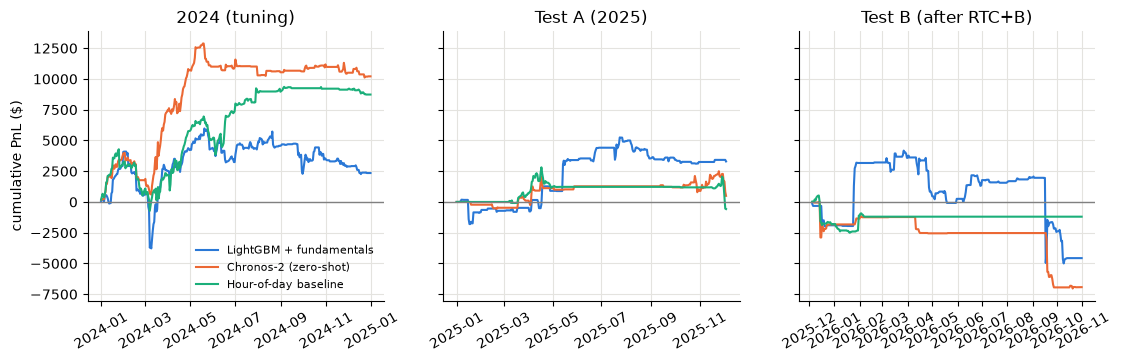

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, p, title in zip(axes, PERIODS, ["2024 (tuning)", "Test A (2025)", "Test B (after RTC+B)"]):
    for m in M:
        d = pd.read_csv(OUTPUT / "backtest" / f"daily_{m}_{p}.csv", parse_dates=["delivery_date"])
        ax.plot(d.delivery_date, d.pnl.cumsum(), color=COLORS[m], label=LABELS[m])
    ax.axhline(0, color="gray", lw=1); ax.set_title(title); ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("cumulative PnL ($)"); axes[0].legend(fontsize=8)
fig.savefig(FIG / "equity_curves.png", bbox_inches="tight", dpi=150); plt.show()

- **2024:** Chronos-2 and the baseline look best.
- **Test A:** only LightGBM makes money.
- **Test B (new market):** all three models lose. One hour (17 Sep 2026, −$3,700) causes most of LightGBM's loss.
- Every Sharpe interval contains 0, and the breakeven fee (≈$0.31) is below our $0.50 fee.

## 5. Conclusions

- **Forecasting works:** LightGBM beats Chronos-2 and the baseline in every period.
- **Trading doesn't, yet:** the auction already prices public information; what's left is real-time surprise.
- **The market change matters:** every model lost money after RTC+B. One tuning year from before the change
  isn't enough.
- **Don't trust in-sample results:** the best model on 2024 (Chronos-2) was the worst out of sample.

**Limitations:**
- the fee is assumed;
- collateral and price impact are not modelled.

**Next steps:**
- retrain on post-RTC+B data;
- add planned line outages;
- predict when big errors happen.

**Reproduce:** `uv run python src/lgbm.py test_a` (and `test_b`, and with no argument for 2024), then
`uv run python src/backtest.py`, then rerun this notebook. Run `uv run pytest` for the look-ahead tests.